In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [19]:
FILE_PATH = "college_students_habits_1M.csv"

df = pd.read_csv(FILE_PATH)

print("Full shape (rows, columns):", df.shape)
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nData types:\n", df.dtypes)

display(df.head())

# Reproducible working sample (25,000 rows) for faster plotting & VIF in Jupyter
df_work = df.sample(n=min(25000, len(df)), random_state=RANDOM_STATE).copy()
print("Working sample shape:", df_work.shape)

Full shape (rows, columns): (1000000, 42)

Missing values per column:
 study_hours                    0
attendance                     0
assignment_completion          0
midterm_score                  0
final_score                    0
project_score                  0
backlogs                       0
sleep_hours                    0
stress                         0
anxiety                        0
depression                     0
motivation                     0
concentration                  0
time_management                0
self_discipline                0
social_media_hours             0
gaming_hours                   0
netflix_hours                  0
screen_time                    0
physical_activity              0
junk_food_frequency            0
caffeine_mg                    0
late_night_frequency           0
procrastination_score          0
family_income                  0
parental_education_level       0
internet_quality               0
library_visits                 0
onlin

,study_hours,attendance,assignment_completion,midterm_score,final_score,project_score,backlogs,sleep_hours,stress,anxiety,...,hostel_student,extracurricular_hours,phone_unlocks_per_day,previous_gpa,class_participation,weekly_study_sessions,group_study_hours,financial_stress,gpa,performance_level
0,3.014684,67.00599,51.595387,57.211285,61.653540,65.397200,4,5.993893,4.287966,58.146000,...,0,1.958940,73.727480,5.721128,3.587111,2.814086,1.814086,5.491878,0.546729,Low
1,3.665277,73.28455,69.749020,57.552320,62.062782,65.715500,3,6.949383,1.841224,41.945290,...,0,3.146447,48.468456,5.755232,4.820090,2.836821,1.836821,2.876881,0.707133,Low
2,2.703784,72.32519,92.837640,44.568970,46.482760,53.597702,2,6.703293,3.863112,56.555750,...,1,5.551245,46.623684,4.456897,5.493774,1.971265,0.971265,5.704047,0.868230,Low
3,3.445073,74.75687,85.189026,52.040790,55.448948,60.571404,2,6.498832,5.073206,65.171420,...,1,4.543216,47.909600,5.204079,5.481987,2.469386,1.469386,6.596658,0.729216,Low
4,0.192687,55.05021,64.520620,32.815000,32.378000,42.627330,5,6.552570,1.000000,30.725826,...,1,4.447042,73.316520,3.281500,2.822375,1.187667,0.187667,4.602954,0.370964,Low


Working sample shape: (25000, 42)


Rows after cleaning: 25000


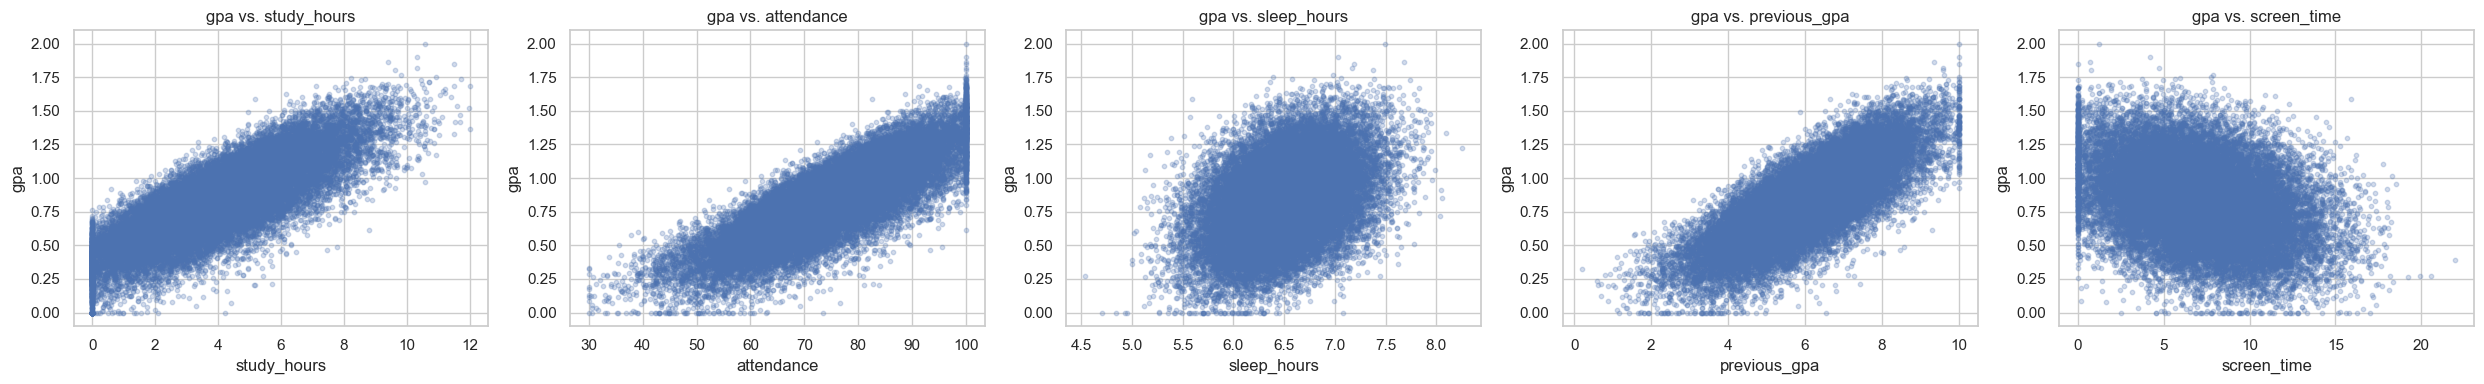

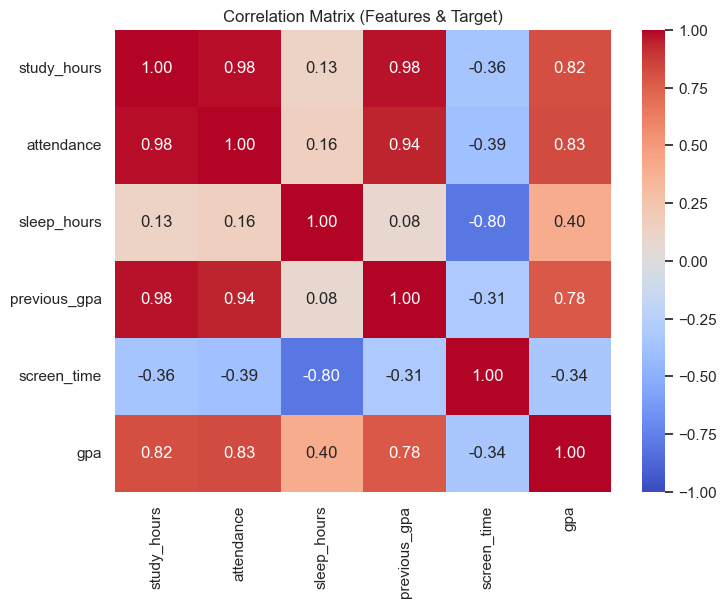


Correlation with target (sorted):
gpa             1.000000
attendance      0.825298
study_hours     0.816581
previous_gpa    0.780773
sleep_hours     0.400561
screen_time    -0.343094
Name: gpa, dtype: float64


In [20]:
TARGET = "gpa"
FEATURES = [
    "study_hours",
    "attendance",
    "sleep_hours",
    "previous_gpa",
    "screen_time",
]

cols_needed = FEATURES + [TARGET]
df_clean = df_work[cols_needed].drop_duplicates().dropna().copy()
print("Rows after cleaning:", len(df_clean))

# Scatter plots of target vs. each feature
fig, axes = plt.subplots(1, len(FEATURES), figsize=(5 * len(FEATURES), 4))
for ax, col in zip(axes, FEATURES):
    ax.scatter(df_clean[col], df_clean[TARGET], alpha=0.25, s=10)
    ax.set_title(f"{TARGET} vs. {col}")
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET)

plt.tight_layout()
plt.show()

# Correlation matrix & labeled heatmap
corr_matrix = df_clean[cols_needed].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix (Features & Target)")
plt.show()

print("\nCorrelation with target (sorted):")
print(corr_matrix[TARGET].sort_values(ascending=False))

In [21]:
hand_cols = ["study_hours", "attendance"]
hand_df = df_clean[hand_cols + [TARGET]].iloc[:6].copy()
display(hand_df)

x1 = hand_df["study_hours"].to_numpy(dtype=float)
x2 = hand_df["attendance"].to_numpy(dtype=float)
y_hand = hand_df[TARGET].to_numpy(dtype=float)

# Design matrix X with leading column of ones: [1, X1, X2]
X_hand = np.column_stack([np.ones(len(hand_df)), x1, x2])

XtX = X_hand.T @ X_hand
Xty = X_hand.T @ y_hand
b_hand = np.linalg.solve(XtX, Xty)

print("Design Matrix X:\n", X_hand)
print("\nX^T X:\n", XtX)
print("\nX^T y:\n", Xty)
print("\nSolved coefficients b = [b0, b1, b2]:\n", b_hand)

b0, b1, b2 = b_hand
print(f"\nMini-sample equation: {TARGET} = {b0:.6f} + ({b1:.6f})*study_hours + ({b2:.6f})*attendance")

y_pred_row0 = b0 + b1 * x1[0] + b2 * x2[0]
residual_row0 = y_hand[0] - y_pred_row0
print(f"Row 0 -> Actual: {y_hand[0]:.6f}, Predicted: {y_pred_row0:.6f}, Residual: {residual_row0:.6f}")

# Verify with scikit-learn on the same 6-row, 2-feature sample
sk_hand_model = LinearRegression().fit(hand_df[hand_cols], y_hand)
print("\nSklearn verification on same 6 rows:")
print("Intercept (b0):", sk_hand_model.intercept_)
print("Coefficients [b1, b2]:", sk_hand_model.coef_)

,study_hours,attendance,gpa
987231,1.187606,57.725986,0.516767
79954,6.130750,86.580180,1.176744
567130,2.269112,65.710120,0.815560
500891,4.013676,74.983380,1.092926
55399,0.000000,42.148310,0.267488
135049,1.096497,56.234120,0.341677


Design Matrix X:
 [[ 1.         1.1876062 57.725986 ]
 [ 1.         6.1307497 86.58018  ]
 [ 1.         2.2691119 65.71012  ]
 [ 1.         4.0136757 74.98338  ]
 [ 1.         0.        42.14831  ]
 [ 1.         1.0964968 56.23412  ]]

X^T X:
 [[6.00000000e+00 1.46976403e+01 3.83382096e+02]
 [1.46976403e+01 6.14572670e+01 1.11108027e+03]
 [3.83382096e+02 1.11108027e+03 2.57075005e+04]]

X^T y:
 [  4.21116209  14.4399338  297.74350326]

Solved coefficients b = [b0, b1, b2]:
 [-0.47067332  0.0513726   0.01638091]

Mini-sample equation: gpa = -0.470673 + (0.051373)*study_hours + (0.016381)*attendance
Row 0 -> Actual: 0.516767, Predicted: 0.535941, Residual: -0.019174

Sklearn verification on same 6 rows:
Intercept (b0): -0.47067332261992034
Coefficients [b1, b2]: [0.0513726  0.01638091]


In [22]:
X = df_clean[FEATURES].copy()
y = df_clean[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")

# Single-feature model using strongest correlated feature with TARGET
corr_with_target = df_clean[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET)
best_feature = corr_with_target.abs().idxmax()
print(f"Most correlated feature with {TARGET}: {best_feature} (r = {corr_with_target[best_feature]:.4f})")

single_model = LinearRegression()
single_model.fit(X_train[[best_feature]], y_train)
y_pred_single = single_model.predict(X_test[[best_feature]])

print("\n--- Single-Feature Model ---")
print(f"Intercept: {single_model.intercept_:.6f}")
print(f"Coefficient ({best_feature}): {single_model.coef_[0]:.6f}")
print(f"Test R^2: {r2_score(y_test, y_pred_single):.6f}")

# Multiple linear regression model on all selected FEATURES
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)
y_pred_multi = multi_model.predict(X_test)

coef_df = pd.DataFrame({
    "feature": FEATURES,
    "raw_coefficient": multi_model.coef_,
})

# Standardize features (fitted strictly on X_train) to compare relative coefficient scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
scaled_model = LinearRegression().fit(X_train_scaled, y_train)
coef_df["standardized_coefficient"] = scaled_model.coef_

print("\n--- Multiple Linear Regression Model ---")
print(f"Intercept: {multi_model.intercept_:.6f}")
display(coef_df)

terms = [f"({row.raw_coefficient:.6f} * {row.feature})" for _, row in coef_df.iterrows()]
equation = f"{TARGET} = {multi_model.intercept_:.6f} + " + " + ".join(terms)
print("\nFitted Equation:\n", equation)

Training rows: 20000 | Test rows: 5000
Most correlated feature with gpa: attendance (r = 0.8253)

--- Single-Feature Model ---
Intercept: -0.576747
Coefficient (attendance): 0.018814
Test R^2: 0.698115

--- Multiple Linear Regression Model ---
Intercept: -3.999372


,feature,raw_coefficient,standardized_coefficient
0,study_hours,0.062584,0.138106
1,attendance,0.011780,0.151874
2,sleep_hours,0.515430,0.224864
3,previous_gpa,-0.005509,-0.008248
4,screen_time,0.053682,0.184437



Fitted Equation:
 gpa = -3.999372 + (0.062584 * study_hours) + (0.011780 * attendance) + (0.515430 * sleep_hours) + (-0.005509 * previous_gpa) + (0.053682 * screen_time)


In [23]:
def adjusted_r2(r2, n_samples, n_features):
    return 1 - ((1 - r2) * (n_samples - 1)) / (n_samples - n_features - 1)

def regression_metrics(y_true, y_pred, n_features):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = adjusted_r2(r2, len(y_true), n_features)
    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Adjusted_R2": adj_r2,
    }

comparison_sample = pd.DataFrame({
    f"Actual_{TARGET}": y_test.values[:10],
    f"Pred_Single ({best_feature})": y_pred_single[:10],
    "Pred_Multi": y_pred_multi[:10],
})
comparison_sample["Error_Multi (Actual - Pred)"] = (
    comparison_sample[f"Actual_{TARGET}"] - comparison_sample["Pred_Multi"]
)
display(comparison_sample)

metrics_single = regression_metrics(y_test, y_pred_single, n_features=1)
metrics_multi = regression_metrics(y_test, y_pred_multi, n_features=len(FEATURES))

metrics_table = pd.DataFrame(
    [metrics_single, metrics_multi],
    index=[f"Single-Feature ({best_feature})", f"Multiple-Feature ({len(FEATURES)} features)"],
)
display(metrics_table.round(6))

# Variance Inflation Factor (VIF)
X_vif = X_train.assign(const=1.0)
vif_df = pd.DataFrame({
    "feature": X_train.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(len(X_train.columns))],
})
display(vif_df.sort_values("VIF", ascending=False))

,Actual_gpa,Pred_Single (attendance),Pred_Multi,Error_Multi (Actual - Pred)
0,0.531162,0.748851,0.814532,-0.283370
1,0.767555,0.773003,0.913677,-0.146122
2,0.910993,0.949490,0.825907,0.085086
3,0.857132,0.976505,1.014800,-0.157668
4,0.759080,0.782503,0.736170,0.022910
5,0.951667,0.900427,0.801061,0.150606
6,0.595097,0.890948,0.834104,-0.239007
7,1.005086,0.811591,0.939703,0.065383
8,0.865927,0.756858,0.709286,0.156641
9,0.590989,1.011187,0.808967,-0.217978


,MAE,MSE,RMSE,R2,Adjusted_R2
Single-Feature (attendance),0.132683,0.027549,0.165980,0.698115,0.698055
Multiple-Feature (5 features),0.082866,0.010857,0.104197,0.881030,0.880910


,feature,VIF
0,study_hours,68.057510
1,attendance,29.407153
3,previous_gpa,24.353694
4,screen_time,3.419405
2,sleep_hours,3.013926


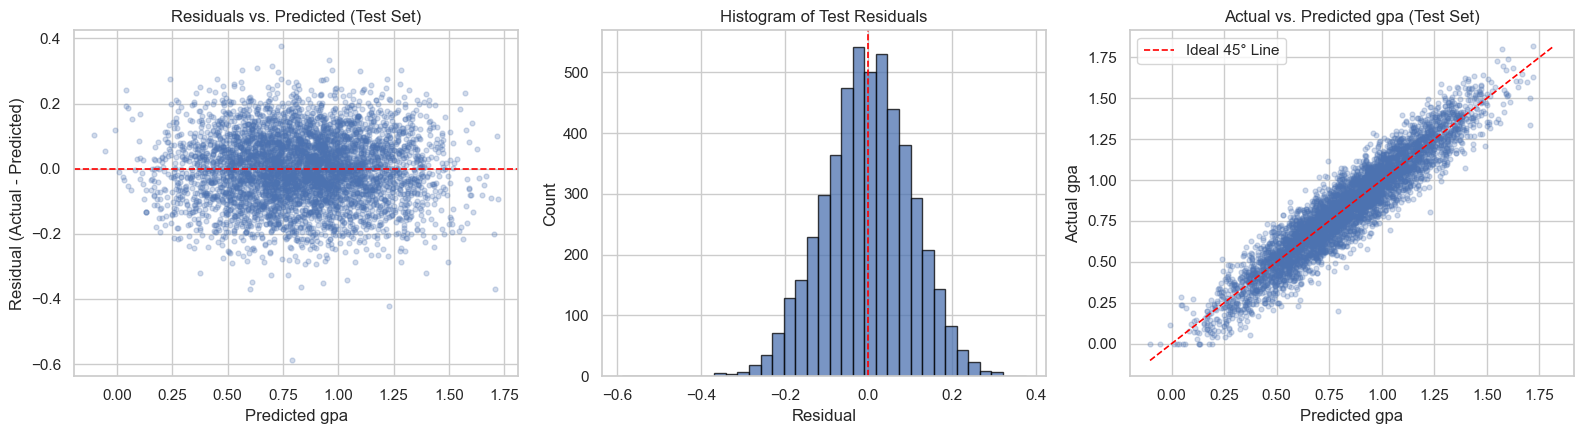

In [24]:
residuals_test = y_test.to_numpy() - y_pred_multi

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(y_pred_multi, residuals_test, alpha=0.25, s=12)
axes[0].axhline(0, color="red", linestyle="--", linewidth=1.2)
axes[0].set_title("Residuals vs. Predicted (Test Set)")
axes[0].set_xlabel(f"Predicted {TARGET}")
axes[0].set_ylabel("Residual (Actual - Predicted)")

axes[1].hist(residuals_test, bins=35, edgecolor="black", alpha=0.75)
axes[1].axvline(0, color="red", linestyle="--", linewidth=1.2)
axes[1].set_title("Histogram of Test Residuals")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Count")

min_val = min(y_test.min(), y_pred_multi.min())
max_val = max(y_test.max(), y_pred_multi.max())
axes[2].scatter(y_pred_multi, y_test, alpha=0.25, s=12)
axes[2].plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=1.2, label="Ideal 45° Line")
axes[2].set_title(f"Actual vs. Predicted {TARGET} (Test Set)")
axes[2].set_xlabel(f"Predicted {TARGET}")
axes[2].set_ylabel(f"Actual {TARGET}")
axes[2].legend()

plt.tight_layout()
plt.show()

In [25]:
new_student_data = {
    col: round(float(X_train[col].median()), 2)
    for col in FEATURES
}

if "study_hours" in new_student_data:
    s_min, s_max = float(X_train["study_hours"].min()), float(X_train["study_hours"].max())
    candidate = round(float(X_train["study_hours"].quantile(0.75)), 2)
    if s_min <= candidate <= s_max:
        new_student_data["study_hours"] = candidate

new_record = pd.DataFrame([new_student_data])[FEATURES]

out_of_range = {
    col: (float(X_train[col].min()), float(X_train[col].max()))
    for col in FEATURES
    if not (float(X_train[col].min()) <= new_record[col].iloc[0] <= float(X_train[col].max()))
}

predicted_gpa = float(multi_model.predict(new_record)[0])

display(new_record)
print(f"Predicted {TARGET}: {predicted_gpa:.4f} GPA points")
print("Out-of-range features:", out_of_range if out_of_range else "None (all values within training range)")

,study_hours,attendance,sleep_hours,previous_gpa,screen_time
0,5.57,75.11,6.5,6.02,6.98


Predicted gpa: 0.9258 GPA points
Out-of-range features: None (all values within training range)
